# 05 - Execution: running the trained agents

This notebook is the **execution deliverable**. It loads the three trained agents
(DQN, DDQN, PPO), runs each for the **same 30 test episodes** on `LunarLander-v3`
with **greedy (deterministic) action selection**, and reports:

- average test reward (mean +/- std, min, max)
- average episode length
- number / rate of solved episodes (return >= 200)

It then renders a **GIF of one landing per agent** into `../figures/`.
All three agents use the identical environment, seed set, and evaluation protocol.

In [1]:
import os, json
import numpy as np
import torch
import torch.nn as nn
import gymnasium as gym
import imageio.v2 as imageio
from IPython.display import Image, display

DEVICE = torch.device('cpu')
ENV_ID = 'LunarLander-v3'
N_TEST = 30
FIG_DIR = '../figures'; os.makedirs(FIG_DIR, exist_ok=True)
print('device', DEVICE, '| env', ENV_ID, '| test episodes', N_TEST)

device cpu | env LunarLander-v3 | test episodes 30


In [2]:
# --- Network definitions (must match the training notebooks) ---
class QNetwork(nn.Module):
    """DQN and DDQN share this 128-64 architecture."""
    def __init__(self, obs_dim, n_actions):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, n_actions),
        )
    def forward(self, x):
        return self.net(x)

class PolicyNetwork(nn.Module):
    def __init__(self, obs_dim, n_actions):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, n_actions),
        )
    def forward(self, x):
        return self.net(x)

_probe = gym.make(ENV_ID)
OBS_DIM = _probe.observation_space.shape[0]
N_ACTIONS = _probe.action_space.n
_probe.close()

def load_q(path):
    net = QNetwork(OBS_DIM, N_ACTIONS).to(DEVICE)
    net.load_state_dict(torch.load(path, map_location=DEVICE)); net.eval(); return net

def load_policy(path):
    net = PolicyNetwork(OBS_DIM, N_ACTIONS).to(DEVICE)
    net.load_state_dict(torch.load(path, map_location=DEVICE)); net.eval(); return net

def q_action(net, obs):
    with torch.no_grad():
        return int(net(torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)).argmax(-1).item())

def policy_action(net, obs):
    with torch.no_grad():
        return int(torch.argmax(net(torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)), -1).item())

AGENTS = {
    'DQN':  dict(net=load_q('../models/dqn/dqn_final.pt'),        act=q_action),
    'DDQN': dict(net=load_q('../models/ddqn/ddqn_final.pt'),      act=q_action),
    'PPO':  dict(net=load_policy('../models/ppo/ppo_policy_final.pt'), act=policy_action),
}
print('loaded:', list(AGENTS))

loaded: ['DQN', 'DDQN', 'PPO']


In [3]:
def test_agent(net, act_fn, n_episodes=N_TEST):
    """Run n greedy episodes with a fixed shared seed set; return per-episode stats."""
    env = gym.make(ENV_ID)
    rewards, lengths = [], []
    for i in range(n_episodes):
        obs, _ = env.reset(seed=20_000 + i)   # same seeds across all three agents
        done = False; R = 0.0; steps = 0
        while not done:
            obs, r, term, trunc, _ = env.step(act_fn(net, obs))
            done = term or trunc; R += r; steps += 1
        rewards.append(R); lengths.append(steps)
    env.close()
    rewards = np.array(rewards); lengths = np.array(lengths)
    return {
        'mean_reward': float(rewards.mean()), 'std_reward': float(rewards.std()),
        'min_reward': float(rewards.min()), 'max_reward': float(rewards.max()),
        'avg_length': float(lengths.mean()),
        'solved_episodes': int((rewards >= 200).sum()), 'solved_rate': float((rewards >= 200).mean()),
        'rewards': rewards.tolist(),
    }

results = {name: test_agent(a['net'], a['act']) for name, a in AGENTS.items()}

import pandas as pd
summary = pd.DataFrame({
    name: {
        'Mean reward': f"{r['mean_reward']:.1f} +/- {r['std_reward']:.1f}",
        'Min / Max': f"{r['min_reward']:.0f} / {r['max_reward']:.0f}",
        'Avg length': f"{r['avg_length']:.0f}",
        'Solved (of 30)': r['solved_episodes'],
        'Solved rate': f"{r['solved_rate']:.0%}",
    } for name, r in results.items()
}).T
print(f"Test evaluation over {N_TEST} deterministic episodes\n")
print(summary.to_string())

with open('../experiments/test_results.json', 'w') as f:
    json.dump(results, f, indent=2)
print('\nSaved ../experiments/test_results.json')
summary

Test evaluation over 30 deterministic episodes

          Mean reward  Min / Max Avg length Solved (of 30) Solved rate
DQN    239.2 +/- 48.6  108 / 301        430             24         80%
DDQN  166.5 +/- 109.7  -17 / 302        370             14         47%
PPO    215.7 +/- 79.5  -27 / 276        402             24         80%

Saved ../experiments/test_results.json


,Mean reward,Min / Max,Avg length,Solved (of 30),Solved rate
DQN,239.2 +/- 48.6,108 / 301,430,24,80%
DDQN,166.5 +/- 109.7,-17 / 302,370,14,47%
PPO,215.7 +/- 79.5,-27 / 276,402,24,80%


In [4]:
def render_gif(net, act_fn, out_path, max_steps=1000, seed=20_000, stride=2, fps=30):
    """Roll out one greedy episode and save it as a GIF."""
    env = gym.make(ENV_ID, render_mode='rgb_array')
    obs, _ = env.reset(seed=seed); done = False; frames = []; steps = 0; R = 0.0
    while not done and steps < max_steps:
        frames.append(env.render())
        obs, r, term, trunc, _ = env.step(act_fn(net, obs))
        done = term or trunc; R += r; steps += 1
    frames.append(env.render()); env.close()
    imageio.mimsave(out_path, frames[::stride], fps=fps)
    print(f'{out_path}: return {R:.1f}, {steps} steps, {len(frames[::stride])} frames')
    return R

gif_paths = {}
for name, a in AGENTS.items():
    p = f'{FIG_DIR}/{name.lower()}_agent.gif'
    render_gif(a['net'], a['act'], p)
    gif_paths[name] = p

../figures/dqn_agent.gif: return 223.9, 404 steps, 203 frames


../figures/ddqn_agent.gif: return 21.2, 189 steps, 95 frames


../figures/ppo_agent.gif: return 240.5, 517 steps, 259 frames


DQN


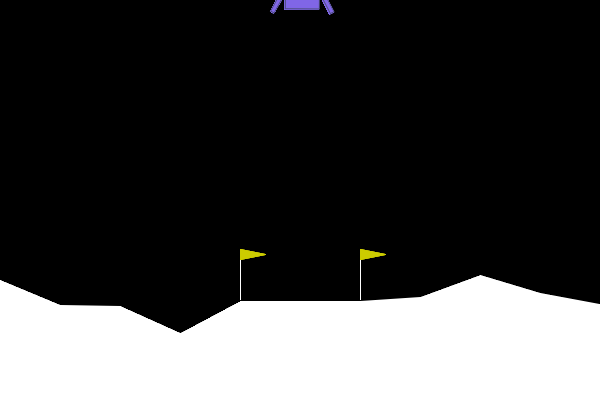

DDQN


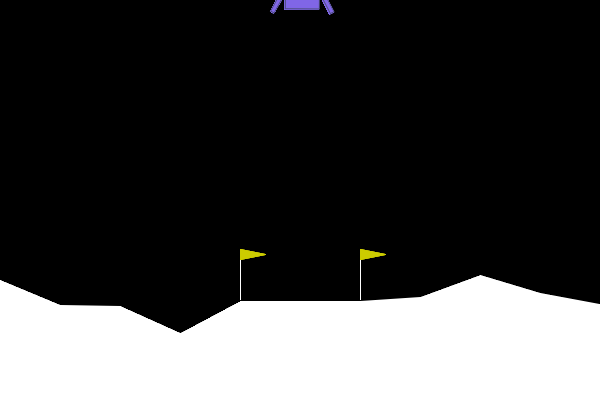

PPO


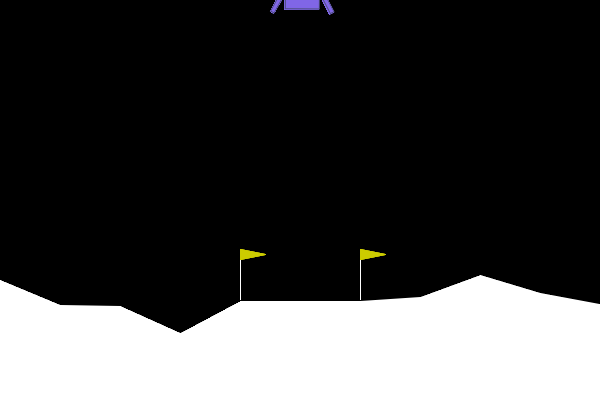

In [5]:
# Display the three landings inline
for name, p in gif_paths.items():
    print(name)
    display(Image(filename=p))

**Result.** Test statistics are saved to `../experiments/test_results.json` and the
three GIFs to `../figures/{dqn,ddqn,ppo}_agent.gif`. These feed the comparison notebook
(04), which combines them with the training curves to answer the discussion questions.